# Module 2 · A CNN looks at my field
This notebook uses **your** `src/cnn.py` (built with Claude from `docs/cnn_spec.md`).
Put **three photos from your own professional or academic field** in `data/my_field/` (jpg or png), then run it top to bottom.
The figure it saves, `results/my_field_cnn.png`, goes into Assignment 2.1. What you conclude from it is **yours**.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import glob
import numpy as np, matplotlib.pyplot as plt
from PIL import Image
from src import cnn
PHOTOS = sorted(p for p in glob.glob("data/my_field/*") if p.lower().endswith((".jpg", ".jpeg", ".png")))
if len(PHOTOS) < 3:
    print("WARNING: put three photos of YOUR field in data/my_field/. Using the course samples for now.")
    PHOTOS = ["data/m2_samples/pothole.png", "data/m2_samples/street.jpg"]
print(PHOTOS)

['data/my_field\\Object1.jpeg', 'data/my_field\\Object2.jpeg', 'data/my_field\\Object3.jpeg']


## 1. Check your paper sketch
The small CNN of the class activity, traced by your code. Compare every size with your drawing.

In [2]:
for r in cnn.trace(cnn.small_cnn()):
    print(f"{r['layer']:18s} {str(r['shape']):16s} {r['weights']:6d} weights")
print("total:", sum(r["weights"] for r in cnn.trace(cnn.small_cnn())), "weights  |",
      cnn.count_parameters(cnn.small_cnn()), "with biases")
print("one 224 photo through the first layer of ResNet-18:", cnn.output_size(224, 7, padding=3, stride=2))

input              (64, 64, 3)           0 weights
Conv2d             (64, 64, 8)         216 weights
ReLU               (64, 64, 8)           0 weights
MaxPool2d          (32, 32, 8)           0 weights
Conv2d             (32, 32, 16)       1152 weights
ReLU               (32, 32, 16)          0 weights
MaxPool2d          (16, 16, 16)          0 weights
AdaptiveAvgPool2d  (1, 1, 16)            0 weights
Flatten            (16,)                 0 weights
Linear             (2,)                 32 weights
total: 1400 weights  | 1426 with biases
one 224 photo through the first layer of ResNet-18: 112


## 2. What a real network answers, sees and looks at
The first run downloads ResNet-18 (45 MB) once.

ResNet-18: 11,689,512 parameters
data/my_field\Object1.jpeg → bucket 0.18, bow 0.08, ladle 0.07
data/my_field\Object2.jpeg → water bottle 0.90, pop bottle 0.03, water jug 0.03
data/my_field\Object3.jpeg → broom 0.21, water bottle 0.11, quill 0.09


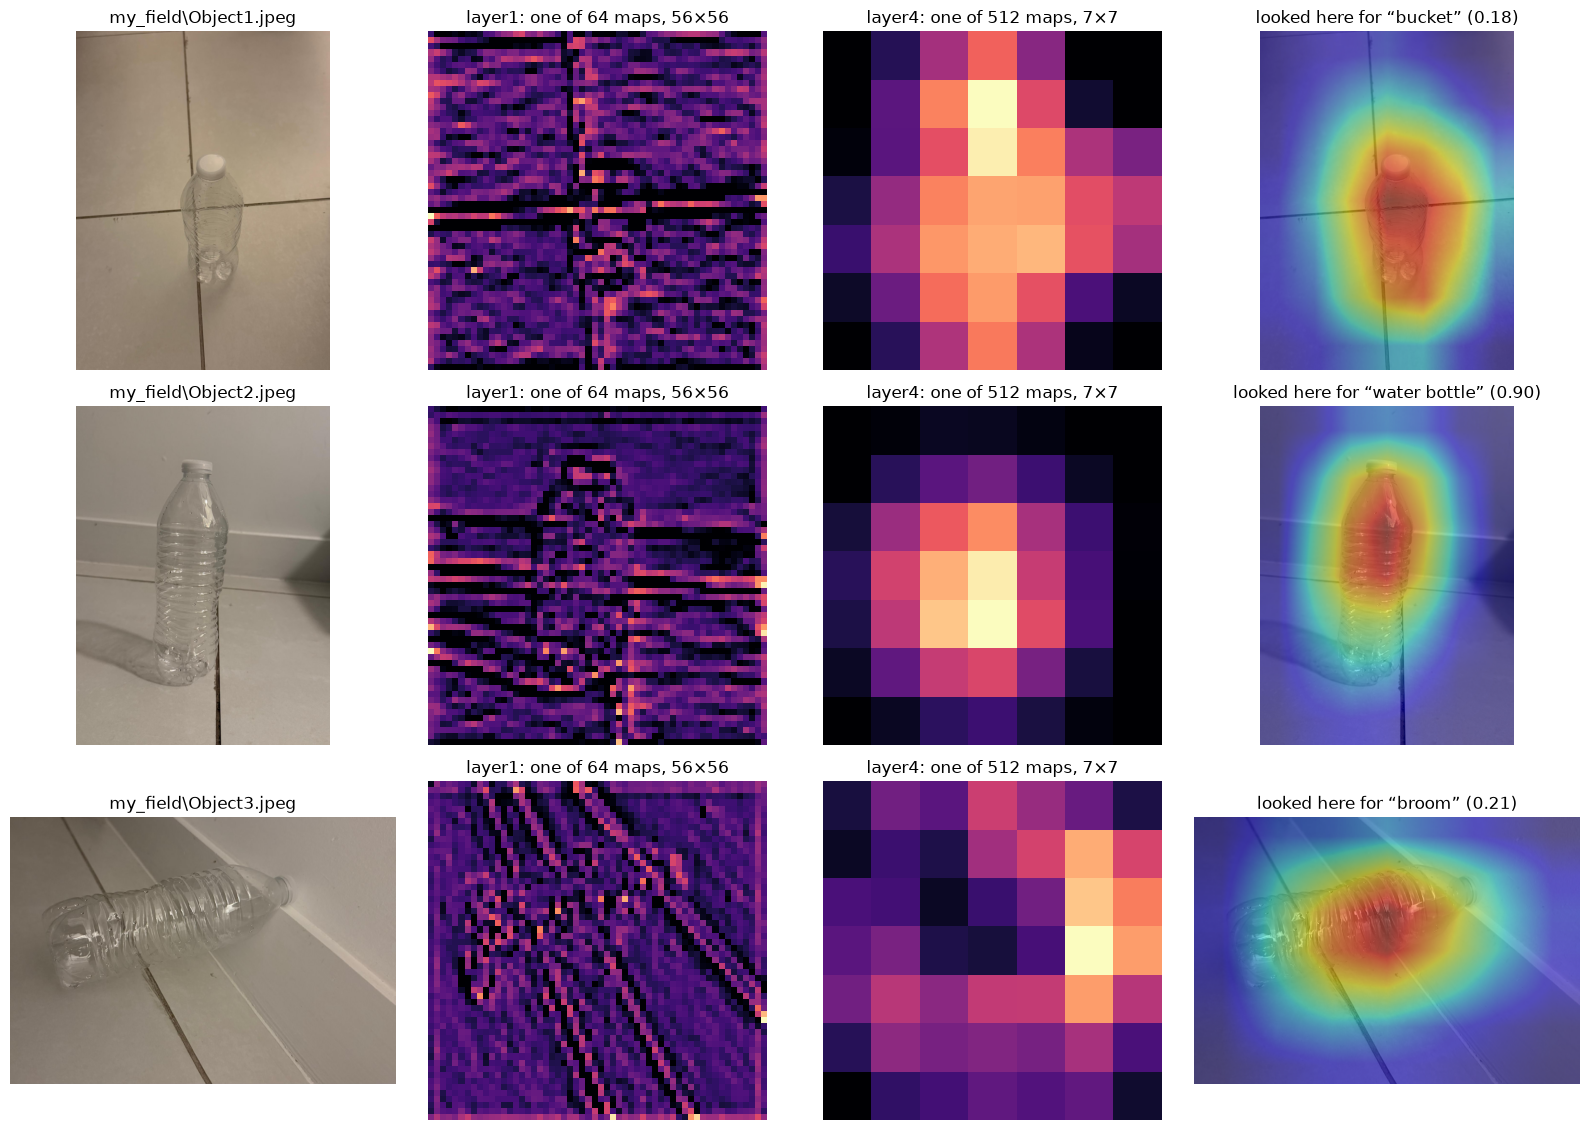

In [3]:
model, preprocess, categories = cnn.load_resnet()
print(f"ResNet-18: {cnn.count_parameters(model):,} parameters")
fig, axes = plt.subplots(len(PHOTOS), 4, figsize=(16, 3.8 * len(PHOTOS)), squeeze=False)
for row, path in zip(axes, PHOTOS):
    rgb = np.array(Image.open(path).convert("RGB"))
    top3 = cnn.classify(model, preprocess, categories, rgb, top=3)
    heat, k, p = cnn.gradcam(model, preprocess, rgb)
    l1 = cnn.feature_maps(model, preprocess, rgb, "layer1"); l4 = cnn.feature_maps(model, preprocess, rgb, "layer4")
    row[0].imshow(rgb); row[0].set_title(path.split("/")[-1])
    row[1].imshow(l1[l1.reshape(64, -1).std(1).argmax()], cmap="magma"); row[1].set_title("layer1: one of 64 maps, 56×56")
    row[2].imshow(l4[l4.reshape(512, -1).mean(1).argmax()], cmap="magma"); row[2].set_title("layer4: one of 512 maps, 7×7")
    row[3].imshow(cnn.overlay(rgb, heat)); row[3].set_title(f"looked here for “{categories[k]}” ({p:.2f})")
    for ax in row: ax.axis("off")
    print(path, "→", ", ".join(f"{n} {q:.2f}" for n, q in top3))
plt.tight_layout(); os.makedirs("results", exist_ok=True); plt.savefig("results/my_field_cnn.png", dpi=120); plt.show()

## My reading (write it yourself — Assignment 2.1)
For each photo:

- **What did it answer?** Is any of the top-3 classes right? ImageNet has 1,000 everyday classes: does it even have a class for your object?
  - Object 1: ResNet-18 answered "bucket" (0.18). This is wrong: the object is a plastic water bottle. ImageNet does have a water bottle class, so the correct class exists. Top-3 from the printed output: bucket 0.18, bow 0.08, ladle 0.07.
  - Object 2: It answered "water bottle" (0.90), which is correct.
  - Object 3: It answered "broom" (0.21). This is wrong: it is still a plastic water bottle, and ImageNet has both classes, but the model chose the wrong one.

- **Where did it look?** Is the red area on the object, or on something else (background, text, a border)?
  - Object 1: The red and yellow areas are mainly around the bottle, but the attention spreads over a large area that includes part of the floor.
  - Object 2: The red and yellow areas are mainly on the body of the bottle, around its middle and upper section. The cap gets less attention, and the floor is mostly blue and green. Compared with Object 1, the red area is narrower and more concentrated on the bottle.
  - Object 3: The red area mainly covers the middle of the bottle's body, not the whole bottle equally. The neck and cap on the right get less attention, and some of the surrounding floor is also included. The bottle lying horizontally changes its appearance compared with the other photos.

- **What does that tell you** about using a CNN for this task in your field without training it on your own photos?

  Objects 1 and 2 both show an upright bottle, but only Object 2 was recognized. The photos differ in four ways:

  - Background: Object 1 shows floor tiles, while Object 2 has a simpler background.
  - Lighting: Object 2 is brighter and more evenly lit.
  - Bottle size: The bottle looks larger in Object 2.
  - Plastic clarity: The shape and details of the plastic are easier to see in Object 2.

  These differences may explain why the CNN recognized Object 2 but confused Object 1 with a bucket. In Object 3, the CNN seems to focus on the bottle's middle shape and does not recognize all of its features as a water bottle.

  **Overall:** Only 1 of 3 predictions was correct. A pretrained CNN is not reliable enough to identify bottles in different positions and conditions without training it on our own photos.